# DiffEdit paper implemenmtation
This notebook is an implementation of [this paper](http://https://arxiv.org/abs/2210.11427). It was a homework as part of Fast.ai's practical deep learning course part 2.
When i got stuck I ocationally referenced [this](https://gist.github.com/kevinbird15/00b7ade94d25e8a1dde3c151b8631ea4) implementation, but have also built upon it. For example, during decoding we now use the noisy latents from the ecoding process of, as opposed to copying the latents of the original image.

## Short description of DiffEdit
This paper aims to modify specific sections of an image based on a given prompt by first automatically generating a mask, and then running diffusion, and at each timestep, replacing the areas outside the mask with the original image with noise from that timestep.
Thus, there are 3 major steps:
1. Generate a mask by:
   - adding some noise to the original image
   - estimating the noise, once conditioned on the text prompt we want to achive (querry), and once on a description of the oiginal image (reference, can also be empty)
   - taking the difference of the estimated noises and binarizing.
2. Encoding:
    - add noise to the original image over some timesteps
    - we use **$r \cdot$num_inference_steps** steps  for encoding, where $r$ is defined as the ecoding ratio
3. Decoding:
    - take the encoded image from the previous step and predict the noise conditional on the querry
    - at each timestep, t, only keep the predictions that fit within the mask from step 1
    - replace the rest with the noised initial image from the ecoding process at the coresponding timestep t.

## Imports

In [1]:
import logging
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from diffusers import StableDiffusionPipeline
from fastcore.all import concat
from huggingface_hub import notebook_login
from PIL import Image

logging.disable(logging.WARNING)

torch.manual_seed(1)
if not (Path.home()/'.cache/huggingface'/'token').exists(): notebook_login()

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

In [2]:
device = "cuda"

## Importing models
Here the text encoder (with tokenizer), vae, unet and scheduler are imported and initialized.

In [3]:
from transformers import CLIPTextModel, CLIPTokenizer
from diffusers import AutoencoderKL, UNet2DConditionModel
from diffusers import LMSDiscreteScheduler

In [4]:
tokenizer = CLIPTokenizer.from_pretrained("openai/clip-vit-large-patch14", torch_dtype=torch.float16)
text_encoder = CLIPTextModel.from_pretrained("openai/clip-vit-large-patch14", torch_dtype=torch.float16).to(device)

# Here we use a different VAE to the original release, which has been fine-tuned for more steps
vae = AutoencoderKL.from_pretrained("stabilityai/sd-vae-ft-ema", torch_dtype=torch.float16).to(device)
unet = UNet2DConditionModel.from_pretrained("CompVis/stable-diffusion-v1-4", subfolder="unet", torch_dtype=torch.float16).to(device)

beta_start,beta_end = 0.00085,0.012
scheduler = LMSDiscreteScheduler(beta_start=beta_start, beta_end=beta_end, beta_schedule="scaled_linear", num_train_timesteps=1000)

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

model.safetensors:   0%|          | 0.00/1.71G [00:00<?, ?B/s]

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

The pipeline is used to generate an initail image, altough any image could work as long as it has the proper shape.

In [5]:
pipe = StableDiffusionPipeline.from_pretrained("CompVis/stable-diffusion-v1-4", variant="fp16", torch_dtype=torch.float16).to(device)

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

model.fp16.safetensors:   0%|          | 0.00/608M [00:00<?, ?B/s]

model.fp16.safetensors:   0%|          | 0.00/246M [00:00<?, ?B/s]

scheduler_config-checkpoint.json:   0%|          | 0.00/209 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

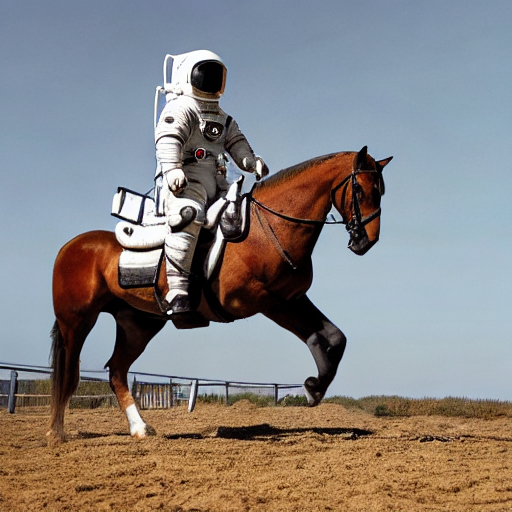

In [6]:
torch.cuda.manual_seed(32)
prompt = "a photograph of an astronaut riding a horse"
init_image = pipe(prompt).images[0]

ref = "astronaut riding a horse"

querry = "astronaut riding a zebra"

init_image

## Defining helper functions
#### text_enc:
Tokenises and encodes the prompts.
#### mk_img:
Converts tensor with image information to PIL image object.
#### img_to_tensor:
Reverse of mk_img, converts PIL image object to tensor.

In [7]:
def text_enc(prompts, maxlen=None):
    if maxlen is None: maxlen = tokenizer.model_max_length
    inp = tokenizer(prompts, padding="max_length", max_length=maxlen, truncation=True, return_tensors="pt")
    return text_encoder(inp.input_ids.to(device))[0].half()

def mk_img(t):
    images = (t/2+0.5).clamp(0,1).detach().cpu().permute(0, 2, 3, 1).numpy()
    return [Image.fromarray(img) for img in (images*255).round().astype("uint8")]

import numpy as np
def img_to_tensor(image):
    """Reverses mk_img: Convert PIL Image back to a Torch tensor"""
    image = np.array(image).astype(np.float16) / 255.0  # Normalize to [0, 1]
    image = torch.from_numpy(image).permute(0, 3, 1, 2) # Convert to (Batch, C, H, W)
    return image * 2 - 1  # Scale to [-1, 1]

#### encode_img:
Takes image tensor and returns latent.

In [8]:
def encode_img(image, latents_dtype, device=device):
    # image as (Batch, H, W, Channel)
    image_tensor = img_to_tensor(image) # (Batch, C, H, W)
    image_tensor = image_tensor.to(device=device, dtype=latents_dtype)

    with torch.no_grad():  # Disable gradient computation for inference
        latents = vae.encode(image_tensor).latent_dist.sample(generator=generator)  # Latent representation

    return latents * 0.18215 # Rescale latent space (this is often used for Stable Diffusion models)


#### get_timestep:
Initialises the cheduler and calculates the number of timestep to be used fro encoding based on **strength** (i.e. encoding ratio) and **num_inference_steps**.

In [9]:
def get_timestep(num_inference_steps, strength, device):
    scheduler.set_timesteps(num_inference_steps)

    num_steps = int(num_inference_steps*strength)
    num_steps = min(num_steps, num_inference_steps)
    timestep = scheduler.timesteps[-num_steps]
    timestep = torch.tensor([timestep], device=device)
    t_start = max(num_inference_steps - num_steps, 0)

    return timestep, t_start

## Diffusion loop

In [10]:
from tqdm.auto import tqdm
import PIL
# apparently using the same generator seed for the querry and reference was the key to getting the noise difference to work
def image2noise(image, prompt, num_inference_steps=50, strength=0.5, guidance=7.5, generator=None, mask=None, device="cuda"):
    bs = len(image)

    # prompt as (Batch, len_prompt)
    text_embeddings = text_enc(prompt)
    uncond_embeddings = text_enc([""]*bs, text_embeddings.shape[1])
    text_embeddings = torch.cat((text_embeddings, uncond_embeddings))

    latents_dtype = text_embeddings.dtype
    init_latents = encode_img(image, latents_dtype, device)
    timestep, t_start = get_timestep(num_inference_steps, strength, device)

    # apply the noise
    noise = torch.randn(init_latents.shape, generator=generator, device=device, dtype=latents_dtype)
    noisy_latents = scheduler.add_noise(init_latents, noise, timestep)
    latents = noisy_latents

    
    timesteps = scheduler.timesteps[t_start:].to(device)
    noise_preds = torch.tensor([], device=device) #(timestep, batch, 4, 64, 64)

    for i, t in enumerate(tqdm(timesteps)):
        if mask is not None:
            # apply noise for current timestep
            noise = torch.randn(init_latents.shape, generator=generator, device=device, dtype=latents_dtype)
            noisy_latents = scheduler.add_noise(init_latents, noise, torch.tensor([t]))
            
            latents = latents*mask + (1-mask)*noisy_latents
            
        input = torch.cat([latents] * 2)
        input = scheduler.scale_model_input(input, t)

        # predict the noise residual
        with torch.no_grad(): c, u = unet(input, t, encoder_hidden_states=text_embeddings).sample.chunk(2)
        pred = u + guidance*(c-u) # perform guidance

        noise_preds = torch.concat((noise_preds, pred))
        
        # compute the "previous" noisy sample
        latents = scheduler.step(pred, t, latents).prev_sample

    with torch.no_grad(): images = vae.decode(1 / 0.18215 * latents).sample

    pil_images = mk_img(images)
    # for img in pil_images: display(img)
    return pil_images, noise_preds


# Step 1: Generate Mask

  0%|          | 0/25 [00:00<?, ?it/s]

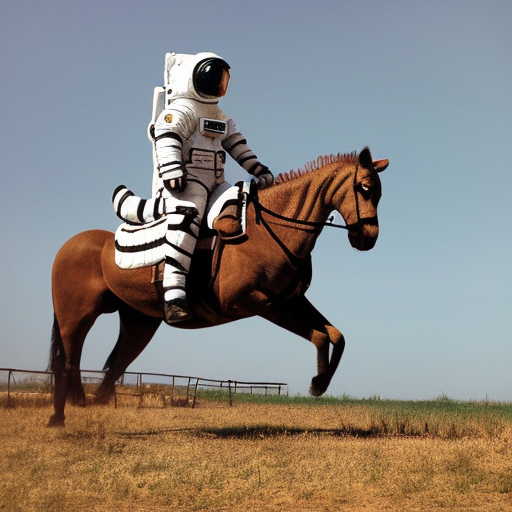

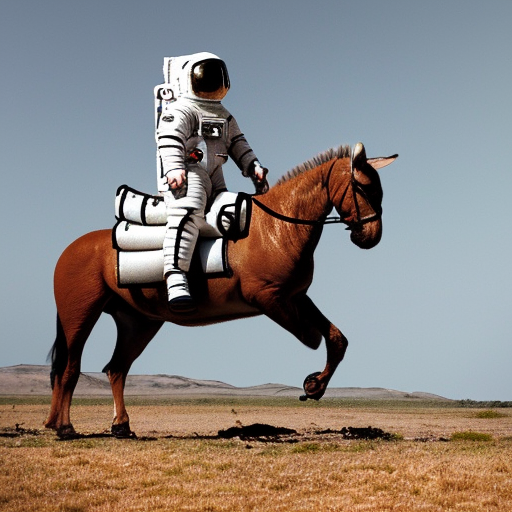

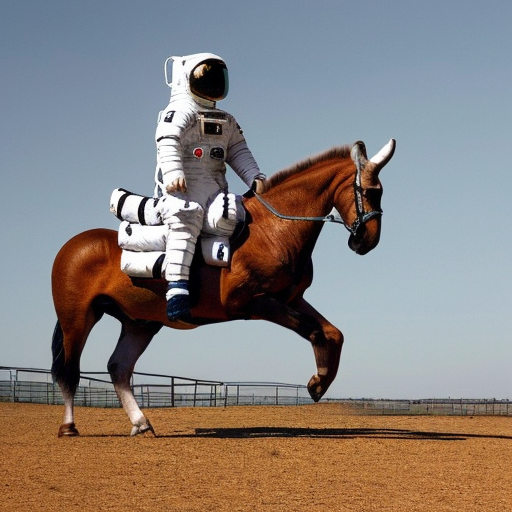

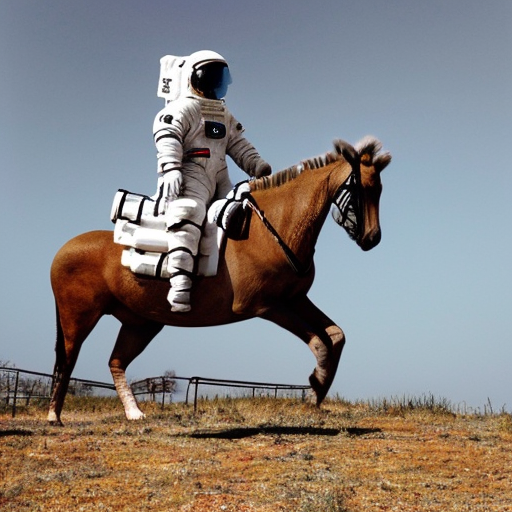

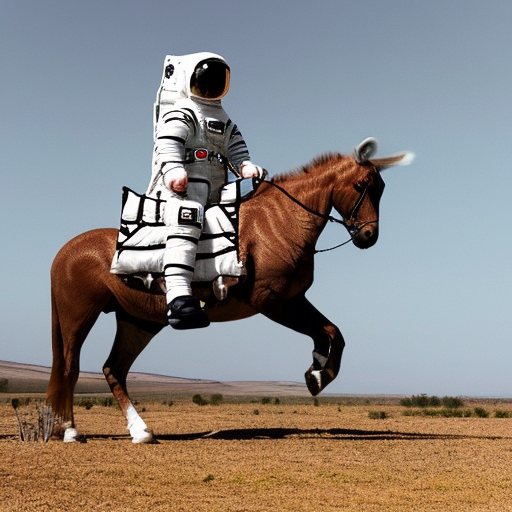

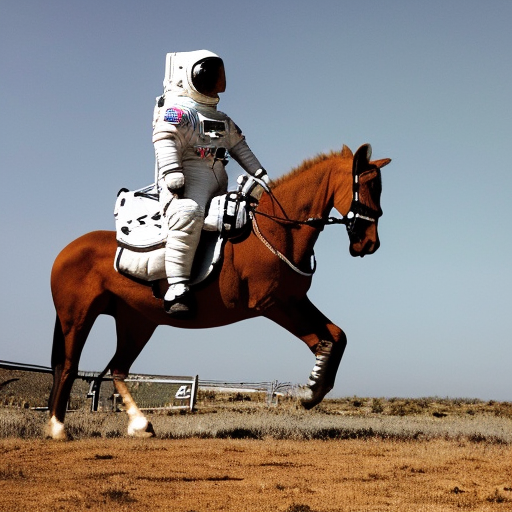

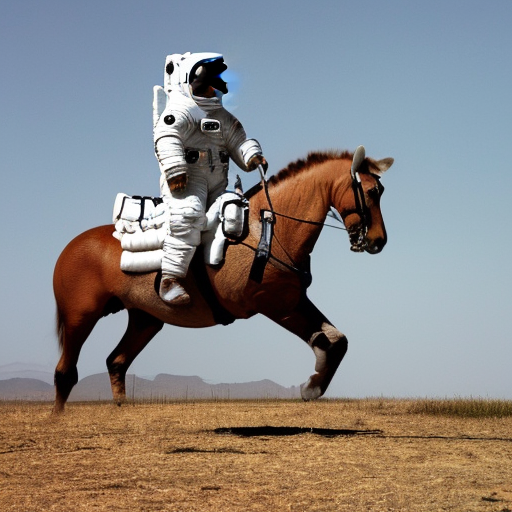

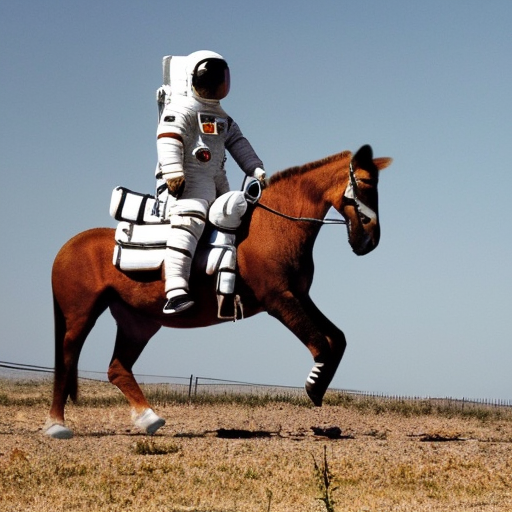

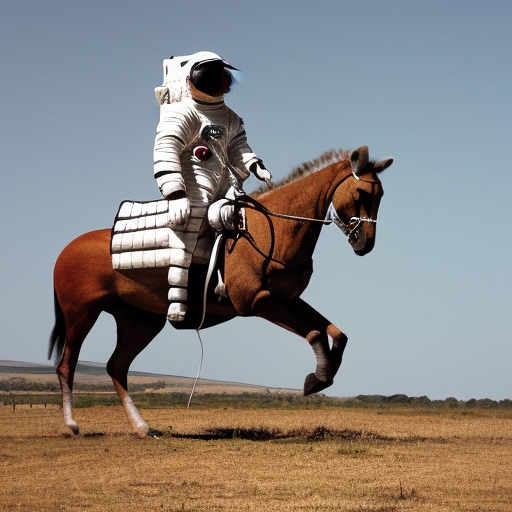

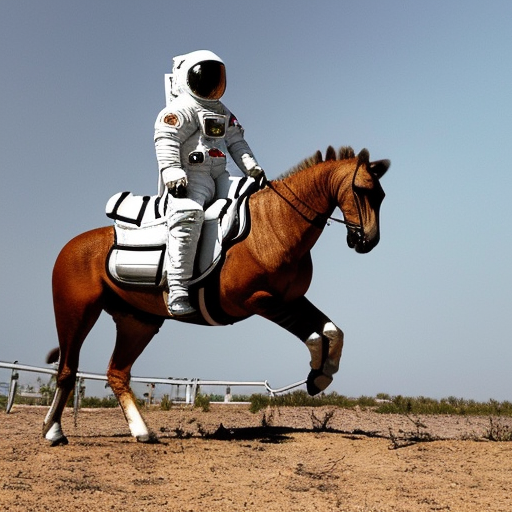

In [11]:
generator = torch.cuda.manual_seed(32)
querry_noises = torch.tensor([], device='cuda')
querry_pil, querry_noises = image2noise([init_image]*10, [querry]*10, generator=generator)
for img in querry_pil: display(img)

  0%|          | 0/25 [00:00<?, ?it/s]

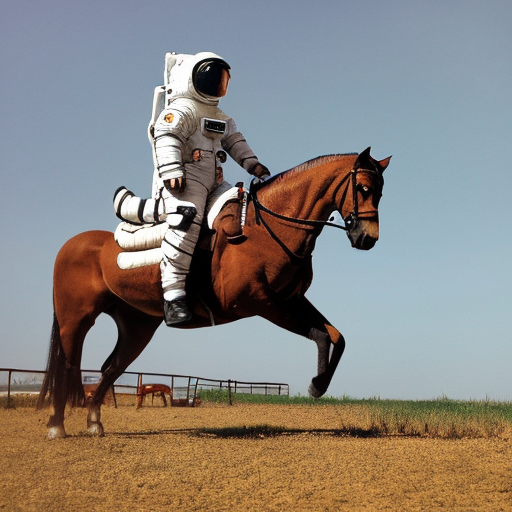

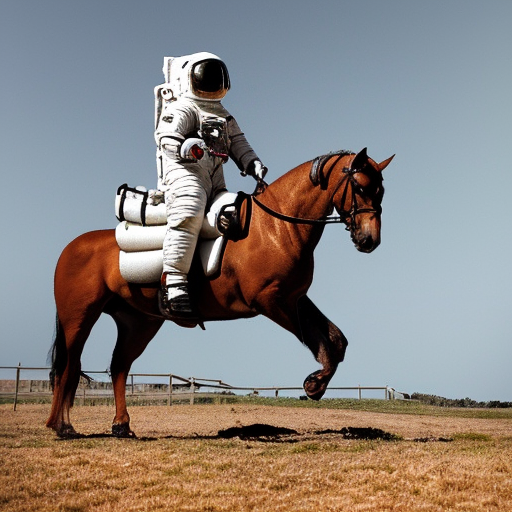

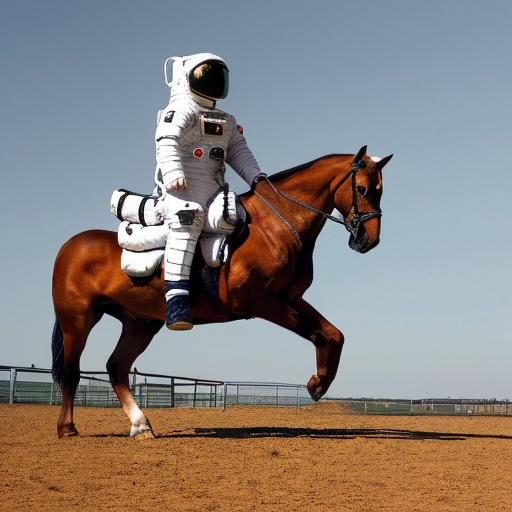

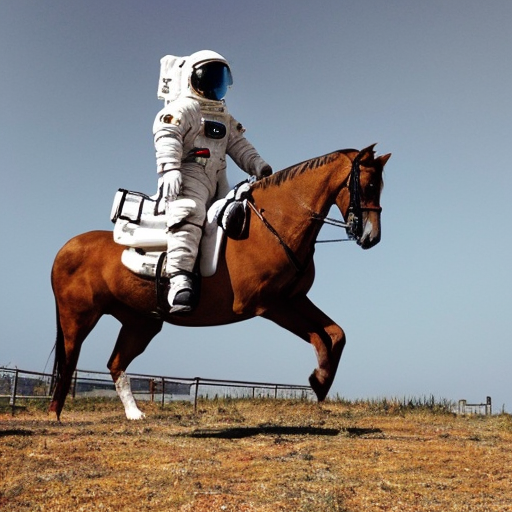

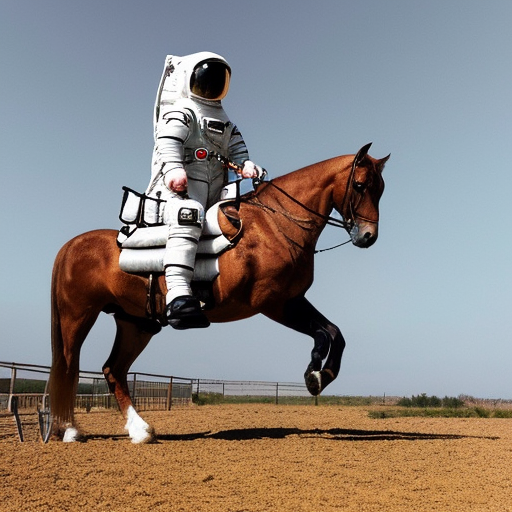

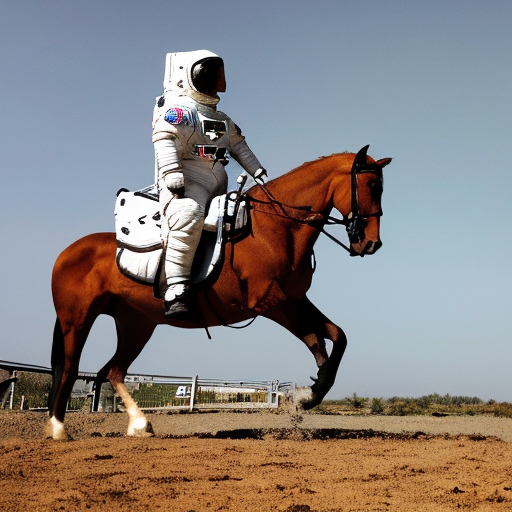

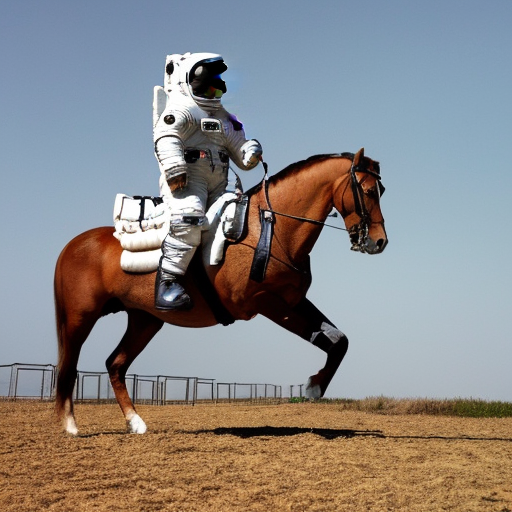

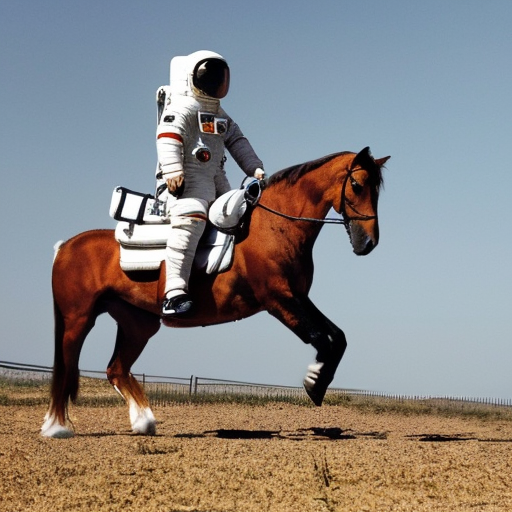

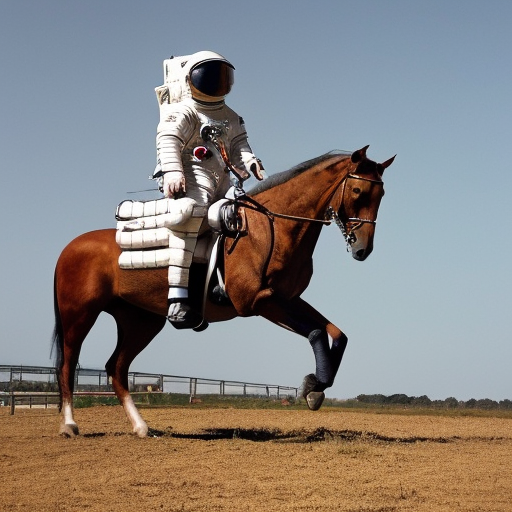

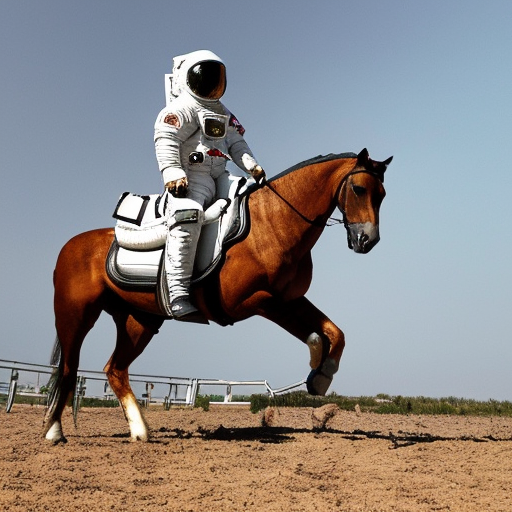

In [12]:
generator = torch.cuda.manual_seed(32)
ref_noises = torch.tensor([], device='cuda')
ref_pil, ref_noises = image2noise([init_image]*10, [ref]*10, generator=generator)
for img in ref_pil: display(img)

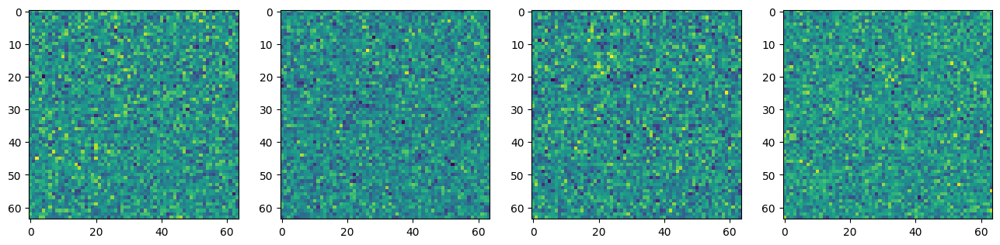

In [13]:
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for c in range(4):
    axs[c].imshow(ref_noises[0][c].cpu())#, cmap='Greys')

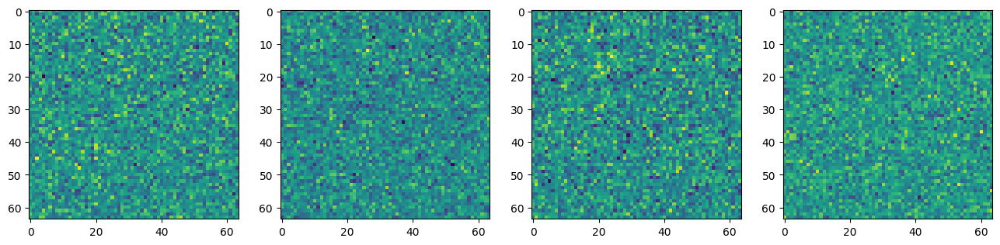

In [14]:
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for c in range(4):
    axs[c].imshow(querry_noises[0][c].cpu())#, cmap='Greys')

In [15]:
diff_noises = (ref_noises - querry_noises).mean(dim=0, keepdim=True)

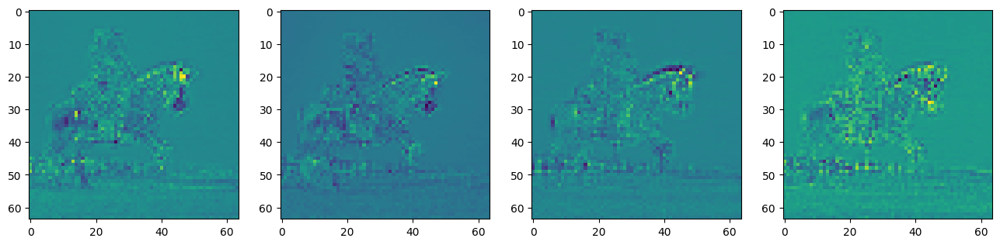

In [16]:
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for c in range(4):
    axs[c].imshow(diff_noises[0][c].cpu())#, cmap='Greys')

In [17]:
import cv2

def extract_channel_mask(img, do_inverse=False):
    kernel = np.ones((3,3),np.uint8)
    img = (img*255).squeeze().cpu().to(torch.uint8).numpy()
    if do_inverse:
        ret2,img2 = cv2.threshold(img,0,255,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)
    else:
        ret2,img2 = cv2.threshold(img,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
    opening = cv2.dilate(img2, kernel)
    return opening

In [18]:
def mk_mask(ref_noises, querry_noises):
    diff_noises = (ref_noises - querry_noises).mean(dim=0, keepdim=True)
    diff_noises_abs = torch.abs(diff_noises)
    norm_noises = (diff_noises_abs - diff_noises_abs.min()) / (diff_noises_abs.max() - diff_noises_abs.min())
    mask = norm_noises.mean(dim=1).squeeze()
    return extract_channel_mask(mask)

In [19]:
final_mask = mk_mask(ref_noises, querry_noises)

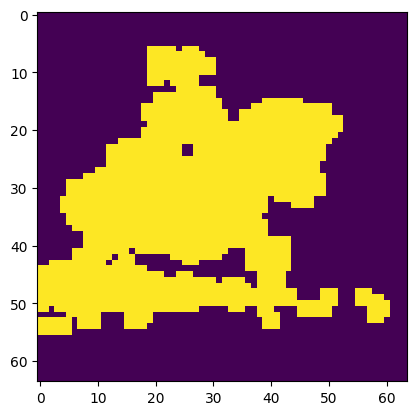

In [20]:
plt.imshow(final_mask)

## Steps 2 & 3: Ecode and Decode

In [21]:
generator = torch.cuda.manual_seed(42)
final_pil, _= image2noise([init_image], num_inference_steps=100, prompt=querry, mask=torch.from_numpy((final_mask/255).astype(int)).cuda(), generator=generator, strength=0.8, guidance=8)

  0%|          | 0/80 [00:00<?, ?it/s]

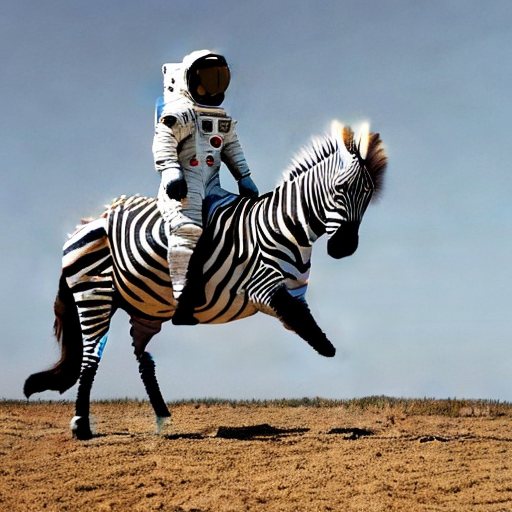

In [22]:
display(final_pil[0])

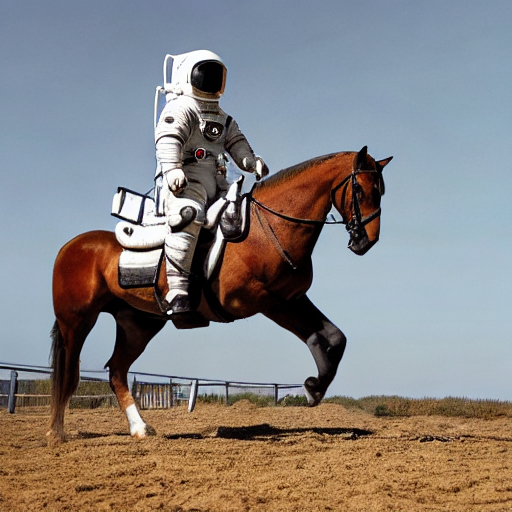

In [23]:
init_image